# PushT Dataset品質改善とPolicy評価

## 目的

`01_roboops_workshop`をベースに、PushT Dataset内の異常episodeを検出する。

検出したepisodeをリプレイで確認し、異常episodeを除外したDatasetで再学習する。


## 検証仮説

PushT Datasetには、以下のような異常が含まれる可能性がある。

- actionが隣接step間で急激に変化する
- actionとagent位置が極端に離れている
- episodeが極端に短い
- NaNまたはinfが含まれている
- agentやT字ブロックが瞬間移動する

本Notebookでは、自動検査で候補を抽出し、リプレイによる目視確認後に除外を決定する。

## 0. 実行環境を固定する【管理】

Dockerは、OSやライブラリなど、実行に必要なものをまとめ、異なるPCでも同じ環境を動かしやすくする仕組みです。DockerfileからDockerイメージを作り、そのイメージをもとにコンテナを起動します。

この教材の実行環境もDockerfileから構築されています。必要なPythonパッケージは `pyproject.toml` で定義し、実際に使用するバージョンは `uv.lock` に記録しています。Dockerのビルド時に、パッケージ管理ツールのuvが `uv.lock` に従ってインストールすることで、同じパッケージ構成を再現できるようにしています。

さらに、乱数seedやCPUの実行条件を固定することで、学習や評価の条件を揃えています。以下では、実行環境と実行条件を確認します。


In [1]:
# 必要なライブラリがインストールされていない場合はインストールします
import sys
import importlib
import importlib.metadata

try:
    importlib.metadata.version('lerobot')
except (NameError, ImportError, importlib.metadata.PackageNotFoundError):
    !pip install -q lerobot gym-pusht

import platform
import torch

print('OS:', platform.platform())
print('Python:', platform.python_version())
print('PyTorch:', torch.__version__)
print('LeRobot:', importlib.metadata.version('lerobot'))
print('gym-pusht:', importlib.metadata.version('gym-pusht'))
print('Device: CPU')

OS: Linux-6.6.159+-x86_64-with-glibc2.39
Python: 3.13.16
PyTorch: 2.11.0+cpu
LeRobot: 0.6.1
gym-pusht: 0.1.8
Device: CPU


## 1. PushTのtaskを確認する【管理】

この教材では、PushTと呼ばれるtaskを題材にRoboOpsに取り組みます。はじめに、PushTがどのようなtaskで、どのような入出力を持つかを確認します。

PushTは、平面上の青いagentを動かし、灰色のT字ブロックを緑の目標領域へ押し込むtaskです。[1] 観測、action、rewardは次のとおりです。

- **Observation**: `[agent_x, agent_y, block_x, block_y, block_angle]`。agentとT字ブロックの位置、ブロックの回転角（radian）
- **Action**: agentが次に向かう目標座標 `(x, y)`
- **Reward**: T字ブロックと目標領域の重なり。重なりが95%を超えるとsuccess


### PushTの初期状態を確認する

ランダムな初期状態を可視化してみましょう。青いagent、灰色のT字ブロック、緑のgoalの位置関係と、初期状態のobservation・rewardを確認します。

> **Tips:** Simulatorのversion、初期化seed、最大step数、成功条件を記録すると、同じ条件で結果を比較できます。


Observation [agent_x, agent_y, block_x, block_y, block_angle]: [ 85.    359.    330.924 304.378   2.253]
Reward: 0.060


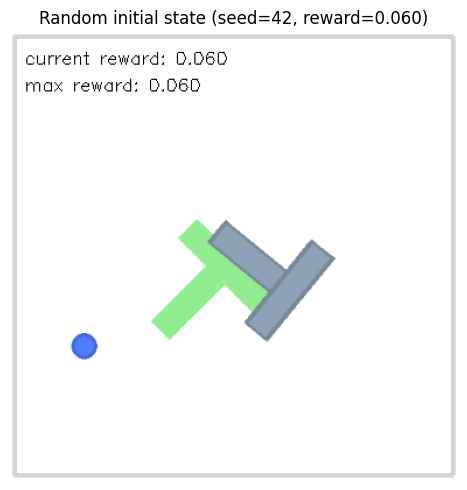

In [2]:
import warnings
import numpy as np
import cv2
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore', message='pkg_resources is deprecated.*')
import gym_pusht  # PushT環境をGymnasiumへ登録
import gymnasium as gym

def show_reward(frame, current, maximum):
    image = np.asarray(frame).copy()
    cv2.rectangle(image, (6, 6), (205, 58), (255, 255, 255), -1)
    cv2.putText(image, f'current reward: {current:.3f}', (12, 27), cv2.FONT_HERSHEY_SIMPLEX, 0.5, 0, 1)
    cv2.putText(image, f'max reward: {maximum:.3f}', (12, 50), cv2.FONT_HERSHEY_SIMPLEX, 0.5, 0, 1)
    return image

preview_env = gym.make(
    'gym_pusht/PushT-v0', obs_type='state', render_mode='rgb_array',
    max_episode_steps=300, visualization_width=384, visualization_height=384,
)
# 同じ初期状態を再現できるよう、seedを固定します。
initial_observation, _ = preview_env.reset(seed=42)
# 状態を進めず、初期配置のgoal coverageからrewardを計算します。
coverage = preview_env.unwrapped._get_coverage()
initial_reward = float(np.clip(coverage / preview_env.unwrapped.success_threshold, 0.0, 1.0))
initial_frame = show_reward(preview_env.render(), initial_reward, initial_reward)
print('Observation [agent_x, agent_y, block_x, block_y, block_angle]:', np.round(initial_observation, 3))
print(f'Reward: {initial_reward:.3f}')
preview_env.close()

plt.figure(figsize=(5, 5))
plt.imshow(initial_frame)
plt.title(f'Random initial state (seed=42, reward={initial_reward:.3f})')
plt.axis('off')
plt.tight_layout()
plt.show()

### Random policyでSimulatorの動きを確認する

動画でPushT taskを可視化してみましょう。Randomなactionでagentを動かし、各時点の `current reward` と、それまでの `max reward` を表示します。

> **Tips:** seedとstep数を記録しておくと、同じ初期状態と動きを再実行できます。


In [3]:
import imageio.v3 as iio
from pathlib import Path
from IPython.display import Video

random_env = gym.make(
    'gym_pusht/PushT-v0', obs_type='state', render_mode='rgb_array',
    max_episode_steps=120, visualization_width=384, visualization_height=384,
)
random_observation, _ = random_env.reset(seed=48)
rng = np.random.default_rng(48)
random_delta = np.zeros(2)
random_coverage = random_env.unwrapped._get_coverage()
random_initial_reward = float(np.clip(
    random_coverage / random_env.unwrapped.success_threshold, 0.0, 1.0,
))
random_frames = [show_reward(random_env.render(), random_initial_reward, random_initial_reward)]
random_max_reward, random_success = random_initial_reward, False
# 前stepの変化量を残し、random actionを連続的にします。
for _ in range(120):
    random_delta = np.clip(0.9 * random_delta + rng.normal(0, 8, size=2), -40, 40)
    random_action = np.clip(random_observation[:2] + random_delta, 0, 512)
    random_observation, reward, terminated, truncated, info = random_env.step(random_action)
    random_max_reward = max(random_max_reward, float(reward))
    random_success = random_success or info['is_success']
    random_frames.append(show_reward(random_env.render(), float(reward), random_max_reward))
    if terminated or truncated:
        break
random_env.close()

RANDOM_VIDEO_PATH = Path('artifacts/evaluation/rollout-random.mp4')
RANDOM_VIDEO_PATH.parent.mkdir(parents=True, exist_ok=True)
iio.imwrite(RANDOM_VIDEO_PATH, np.stack(random_frames), fps=10, codec='libx264')
print(f'Random policy: max reward={random_max_reward:.3f}, success={random_success}')
display(Video(str(RANDOM_VIDEO_PATH), embed=True, width=480))

Random policy: max reward=0.662, success=False


通常の模倣学習では、`Simulator / 実機を用いてデータを収集 → データを前処理 → 学習` と進みます。

今回は120分でRoboOps全体を一周するため、データ収集を省略し、収集済みのPushT DatasetをHugging Faceから取得します。Datasetを受け取り、管理・検証するところから始めます。


## 2. DatasetのIDとversionを記録する【管理】

これから取得する `lerobot/pusht_keypoints` は、先ほど見たPushTの操作軌跡をepisode単位で記録したDatasetです。[2]

Hugging Face Dataset Hubは、Datasetを保存・共有し、IDとrevisionを指定して取得できるサービスです。revisionはDatasetのversionを特定する値で、branch名、tag名、commit hashを指定できます。ここでは更新に左右されず同じDatasetを取得できるよう、commit hashをコード上に記録します。

> **Tips:** Gitはコードの差分管理に向いていますが、大容量のDatasetやモデルweightを直接保存すると、更新のたびに履歴が膨らみ、cloneや取得が重くなります。そのため、コードとconfigはGit / GitHub、DatasetやPolicyはversionを付けて配布・取得しやすいHugging Face、実行環境はDockerで管理します。


In [4]:
# 互換性のあるバージョンの 'av' と 'lerobot[dataset]' をセットアップします
!pip install -q --upgrade av lerobot[dataset]

import warnings
warnings.filterwarnings('ignore', message='IProgress not found.*')

import sys
import importlib
importlib.invalidate_caches()

# インポートの内部キャッシュを強制リセットします
for pkg in list(sys.modules.keys()):
    if 'lerobot' in pkg or 'av' in pkg:
        sys.modules.pop(pkg, None)

from huggingface_hub import hf_hub_download
from lerobot.datasets import LeRobotDataset
from pathlib import Path
import logging

# Datasetが更新されても同じ内容を取得できるよう、revisionを固定します。
DATASET_ID = 'lerobot/pusht_keypoints'
REVISION = 'ace8c161a68bc025c21a5f29f85b86a9a2c5e64b'
RAW_ROOT = Path('data/raw/lerobot_pusht_keypoints') / REVISION
FILES = [
    'meta/info.json', 'meta/stats.json', 'meta/tasks.parquet',
    'meta/episodes/chunk-000/file-000.parquet',
    'data/chunk-000/file-000.parquet',
]
for filename in FILES:
    if not (RAW_ROOT / filename).exists():
        hf_hub_download(
            DATASET_ID, filename, repo_type='dataset',
            revision=REVISION, local_dir=RAW_ROOT,
        )
logging.getLogger('lerobot.utils.import_utils').setLevel(logging.ERROR)
dataset = LeRobotDataset(
    DATASET_ID, root=RAW_ROOT, revision=REVISION, download_videos=False,
)
print(f'Loaded: {DATASET_ID}@{REVISION[:12]} ({dataset.num_episodes} episodes)')

Loaded: lerobot/pusht_keypoints@ace8c161a68b (206 episodes)


### LeRobot Datasetの形式を確認する

LeRobot Datasetは、ロボット学習データを共通の形式で保存・読み込む仕組みです。ロボットごとにカメラ画像、関節角度、keypointsなどの中身は異なりますが、episodeの構造やmetadataの持ち方が揃っているため、`LeRobotDataset` を使って同じ方法で読み込めます。

Datasetにどのfieldがあり、それぞれがどのようなdtype、shape、fpsを持つかというデータ構造の定義を **schema** と呼びます。LeRobot Datasetでは、このschemaがmetadataに記録されています。

まず、metadataに記録されたfieldをすべて表示します。


In [5]:
print('Dataset fields:')
for name in dataset.meta.features:
    print('-', name)


Dataset fields:
- observation.state
- observation.environment_state
- action
- episode_index
- frame_index
- timestamp
- next.reward
- next.done
- next.success
- index
- task_index


### 学習に使うfieldを確認する

PushTでは、1 recordが0.1秒ごとの1時点です。学習に使う主なfieldは次の3つです。

| Field | 入っている値 | 意味 |
|---|---|---|
| `observation.state` | `[agent_x, agent_y]` | 現在のagent位置 |
| `observation.environment_state` | `[x0, y0, ..., x7, y7]` | 現在のT字ブロックを表す8 keypoints |
| `action` | `[target_x, target_y]` | agentが次に向かう位置 |

8 keypointsは、Simulator内部のT字ブロックの位置と回転角から、輪郭上の8点をxy座標へ変換した値です。agent・ブロック・actionを同じxy座標系で扱え、角度の周期性も避けられます。

次のセルでは、この3つのfieldのdtype、shape、fpsをmetadataから表示します。

> **Tips:** schemaをversionと一緒に記録すると、Dataset更新によるfieldやshapeの変化を検出できます。


In [6]:
from IPython.display import Markdown

MAIN_FIELDS = ['observation.state', 'observation.environment_state', 'action']
schema_rows = [
    f"| `{name}` | `{dataset.meta.features[name]['dtype']}` | `{dataset.meta.features[name]['shape']}` | {dataset.meta.features[name]['fps']} |"
    for name in MAIN_FIELDS
]
display(Markdown(
    '| field | dtype | shape | fps |\n|---|---|---|---:|\n' + '\n'.join(schema_rows)
))

| field | dtype | shape | fps |
|---|---|---|---:|
| `observation.state` | `float32` | `(2,)` | 10 |
| `observation.environment_state` | `float32` | `(16,)` | 10 |
| `action` | `float32` | `(2,)` | 10 |

Datasetから必要なfieldを取り出してNumPy配列へ変換し、episode数、shape、先頭recordの値を確認します。


In [7]:
samples = [dataset[index] for index in range(len(dataset))]
agent = torch.stack([row['observation.state'] for row in samples]).numpy()
environment = torch.stack([row['observation.environment_state'] for row in samples]).numpy()
actions = torch.stack([row['action'] for row in samples]).numpy()
episode_index = torch.stack([row['episode_index'] for row in samples]).numpy()
frame_index = torch.stack([row['frame_index'] for row in samples]).numpy()
episodes, lengths = np.unique(episode_index, return_counts=True)

print(f'Episodes: {len(episodes)} / Frames: {len(actions):,}')
print(f'Episode length: min={lengths.min()}, mean={lengths.mean():.1f}, max={lengths.max()}')
print('agent:', agent.shape, 'environment:', environment.shape, 'action:', actions.shape)
print(f"\nEpisode {int(episode_index[0])}, frame {int(frame_index[0])}, time {float(samples[0]['timestamp']):.1f}s")
print('Current agent (x, y):', agent[0].round(1).tolist())
print('T keypoints (x, y):\n', environment[0].reshape(8, 2).round(1))
print('Action target (x, y):', actions[0].round(1).tolist())


Episodes: 206 / Frames: 25,650
Episode length: min=49, mean=124.5, max=246
agent: (25650, 2) environment: (25650, 16) action: (25650, 2)

Episode 0, frame 0, time 0.0s
Current agent (x, y): [222.0, 97.0]
T keypoints (x, y):
 [[282.5 373.6]
 [163.5 389.6]
 [159.5 359.9]
 [278.5 343.9]
 [233.9 349.9]
 [204.1 353.9]
 [192.1 264.7]
 [221.9 260.7]]
Action target (x, y): [233.0, 71.0]


### Datasetの1 episodeをリプレイする

Datasetに記録されたデータをPushT Simulatorで動かし、可視化してみましょう。数値だけでは分かりにくい、青いagent、灰色のT字ブロック、緑のgoal、赤い十字のactionの動きを再生し、時系列として自然に動いているかを確認します。

> **Tips:** schemaと統計が正常でも、座標軸の反転や時系列のずれは見逃すことがあります。機械的なvalidationにリプレイによる目視確認を組み合わせます。


In [8]:
replay_episode = episodes[min(20, len(episodes) - 1)]
mask = episode_index == replay_episode
# 8 keypointsからT字ブロックの初期位置と角度を復元します。
keypoints = environment[mask][0].reshape(8, 2)
angle = np.arctan2(*(keypoints[1] - keypoints[0])[::-1])
rotation = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
block_position = keypoints[0] - rotation @ np.array([-60, 0])

replay_env = gym.make(
    'gym_pusht/PushT-v0', obs_type='state', render_mode='rgb_array',
    max_episode_steps=int(mask.sum()), visualization_width=384, visualization_height=384,
)
replay_env.reset(seed=0)
simulator = replay_env.unwrapped
simulator.agent.position = agent[mask][0].tolist()
simulator.block.angle = float(angle)
simulator.block.position = block_position.tolist()
simulator.space.step(simulator.dt)

replay_frames, replay_max_reward, replay_success = [replay_env.render()], 0.0, False
# Datasetに記録されたactionを順番にSimulatorへ入力します。
for action in actions[mask]:
    _, reward, terminated, truncated, info = replay_env.step(action)
    replay_frames.append(replay_env.render())
    replay_max_reward = max(replay_max_reward, float(reward))
    replay_success = replay_success or info['is_success']
    if terminated or truncated:
        break
replay_env.close()

REPLAY_VIDEO_PATH = Path('artifacts/evaluation/replay-dataset.mp4')
REPLAY_VIDEO_PATH.parent.mkdir(parents=True, exist_ok=True)
iio.imwrite(REPLAY_VIDEO_PATH, np.stack(replay_frames), fps=10, codec='libx264')
print(f'Episode {replay_episode}: max reward={replay_max_reward:.3f}, success={replay_success}')
display(Video(str(REPLAY_VIDEO_PATH), embed=True, width=480))


Episode 20: max reward=1.000, success=True


## 3. Datasetのschemaと品質を確かめる【検証】

ロボットから収集するDatasetは、多数のepisodeを含むため、すべてを目視で確認するのは困難です。そこで、**全recordを自動で検査し、人は代表sampleと検出された異常を確認する**ように役割を分けます。

validatorを作成し、正しいデータとわざと壊したデータを用いて、挙動を確認しましょう。


In [9]:
REQUIRED = ['observation.state', 'observation.environment_state', 'action', 'episode_index']
EXPECTED_SHAPES = {
    'observation.state': (2,),
    'observation.environment_state': (16,),
    'action': (2,),
}

def validate(data):
    # 必須fieldがすべて存在するか
    if any(key not in data for key in REQUIRED):
        return 'FAIL'

    # 各fieldのrecord数が同じで、空ではないか
    counts = [len(data[key]) for key in REQUIRED]
    if counts[0] == 0 or len(set(counts)) != 1:
        return 'FAIL'

    # 各fieldのshapeが定義どおりか
    shapes_ok = all(
        np.asarray(data[key]).ndim == 2
        and np.asarray(data[key]).shape[1:] == shape
        for key, shape in EXPECTED_SHAPES.items()
    ) and np.asarray(data['episode_index']).ndim == 1
    if not shapes_ok:
        return 'FAIL'

    numeric = [data[key].astype(float) for key in REQUIRED[:3]]

    # 数値にNaNやinfが含まれていないか
    if not all(np.isfinite(array).all() for array in numeric):
        return 'FAIL'

    # 座標値が想定範囲を大きく外れていないか
    if not all(np.abs(array).max() <= 1024 for array in numeric):
        return 'FAIL'

    # 各episodeに5 record以上あるか
    episode_lengths = np.unique(data['episode_index'], return_counts=True)[1]
    if episode_lengths.min() < 5:
        return 'FAIL'

    return 'PASS'


### validatorの挙動を確認する

まず、正常なsample dataを通します。


In [10]:
data = {
    'observation.state': np.full((5, 2), 128.0),
    'observation.environment_state': np.full((5, 16), 256.0),
    'action': np.full((5, 2), 130.0),
    'episode_index': np.zeros(5, dtype=int),
}
validate(data)


'PASS'

次に、わざと壊したdataを通します。


In [11]:
broken = {
    'observation.state': np.full((4, 2), np.nan),
    'observation.environment_state': np.full((4, 16), 2048.0),
    'action': np.full((4, 2), 130.0),
    'episode_index': np.zeros(4, dtype=int),
}
validate(broken)


'FAIL'

正常なdataはPASSし、broken dataはFAILしました。最後に、取得したLeRobot Datasetを通します。


In [12]:
downloaded = dict(zip(REQUIRED, [agent, environment, actions, episode_index], strict=True))
validate(downloaded)


'PASS'

取得したDatasetもPASSしたため、学習へ進みます。


##episode単位の特徴量を計算する
各episodeについて、異常判定に使う統計量を作ります。

特徴量の例
length

nan_or_inf

out_of_range

max_action_step

max_agent_step

max_action_state_distance

stationary_ratio

In [13]:
def episode_statistics(state, action, reward, episode_index):
    rows = []

    for ep in np.unique(episode_index):
        mask = episode_index == ep

        ep_state = state[mask]
        ep_action = action[mask]
        ep_reward = reward[mask]

        row = {
            "episode_index": int(ep),
            "length": int(mask.sum()),
            "nan_or_inf": (
                not np.isfinite(ep_state).all()
                or not np.isfinite(ep_action).all()
            ),
        }

        if len(ep_state) >= 2:
            agent_step = np.linalg.norm(
                np.diff(ep_state, axis=0),
                axis=1,
            )
            action_step = np.linalg.norm(
                np.diff(ep_action, axis=0),
                axis=1,
            )
        else:
            agent_step = np.array([])
            action_step = np.array([])

        action_state_distance = np.linalg.norm(
            ep_action - ep_state,
            axis=1,
        )

        row.update({
            "max_agent_step": (
                float(agent_step.max())
                if len(agent_step) else 0.0
            ),
            "max_action_step": (
                float(action_step.max())
                if len(action_step) else 0.0
            ),
            "max_reward": (
                float(ep_reward.max())
                if len(ep_reward) else 0.0
            ),
            "max_action_state_distance": float(
                action_state_distance.max()
            ),
            "stationary_ratio": (
                float(np.mean(action_step < 1e-6))
                if len(action_step) else 1.0
            ),
        })

        rows.append(row)

    return pd.DataFrame(rows)

In [14]:
import pandas as pd

# データセットからreward情報を取得します
rewards = torch.stack([row['next.reward'] for row in samples]).numpy()

stats_df = episode_statistics(agent, actions, rewards, episode_index)
display(stats_df.describe())

,episode_index,length,max_agent_step,max_action_step,max_reward,max_action_state_distance,stationary_ratio
count,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000
mean,102.500000,124.514563,28.335685,47.264250,0.892300,73.386270,0.030861
std,59.611241,35.674371,7.539296,18.831430,0.026535,21.404456,0.026774
min,0.000000,49.000000,12.970042,16.124516,0.813152,32.804646,0.000000
25%,51.250000,99.000000,23.678021,36.013885,0.875597,60.482690,0.013008
50%,102.500000,122.000000,26.891968,42.130690,0.895872,69.513222,0.026215
75%,153.750000,148.000000,31.691111,51.604253,0.910479,81.559772,0.039921
max,205.000000,246.000000,59.188416,136.473434,0.948880,175.654678,0.235294


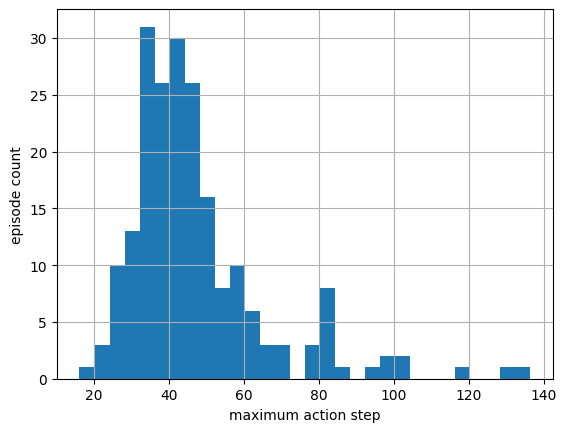

In [15]:
import matplotlib.pyplot as plt

stats_df["max_action_step"].hist(bins=30)
plt.xlabel("maximum action step")
plt.ylabel("episode count")
plt.show()

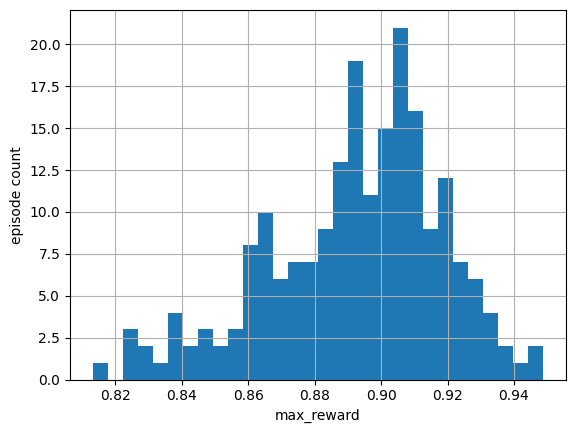

In [16]:
import matplotlib.pyplot as plt

stats_df["max_reward"].hist(bins=30)
plt.xlabel("max_reward")
plt.ylabel("episode count")
plt.show()

通常データの分布から明らかに離れている
かつ
リプレイで不自然な動作が確認できるものを除外対象にする。

仮に判定ルールを規定


In [17]:
MIN_EPISODE_LENGTH = 50
MAX_COORDINATE = 1024
MAX_ACTION_STEP = 80.0
MAX_ACTION_STATE_DISTANCE = 250.0
MAX_STATIONARY_RATIO = 0.10

#REWARDを仮に0.85以下のものを
MAX_REWARD = 0.85

##検出ルールを実装する
異常理由を複数記録できるようにします。

In [18]:
def detect_flags(row):
    flags = []

    #if row["length"] < MIN_EPISODE_LENGTH:
    #    flags.append("too_short")

    #if row["nan_or_inf"]:
    #    flags.append("nan_or_inf")

    #if row["max_action_step"] > MAX_ACTION_STEP:
    #    flags.append("action_jump")

    #if (
    #    row["max_action_state_distance"]
    #    > MAX_ACTION_STATE_DISTANCE
    #):
    #    flags.append("action_far_from_agent")

    #if row["stationary_ratio"] > MAX_STATIONARY_RATIO:
    #    flags.append("mostly_stationary")

    if row["max_reward"] < MAX_REWARD:
        flags.append("low reward")

    return flags


stats_df["flags"] = stats_df.apply(
    detect_flags,
    axis=1,
)

stats_df["candidate"] = stats_df["flags"].map(bool)

candidates = stats_df[stats_df["candidate"]].copy()
display(candidates)

,episode_index,length,nan_or_inf,max_agent_step,max_action_step,max_reward,max_action_state_distance,stationary_ratio,flags,candidate
15,15,153,False,38.427818,83.546394,0.839021,96.652985,0.039474,[low reward],True
42,42,136,False,26.092035,44.011364,0.823223,70.544739,0.029630,[low reward],True
45,45,152,False,29.484184,49.203659,0.831586,76.390007,0.033113,[low reward],True
49,49,83,False,23.542715,40.000000,0.838126,58.336552,0.012195,[low reward],True
53,53,173,False,26.079721,52.924473,0.823558,65.360367,0.017442,[low reward],True
56,56,105,False,26.823565,50.990196,0.846534,70.203232,0.038462,[low reward],True
61,61,150,False,25.382313,44.283180,0.841991,64.346077,0.006711,[low reward],True
95,95,107,False,42.143936,58.034473,0.813152,104.763824,0.028302,[low reward],True
113,113,149,False,29.529373,46.173584,0.837942,78.470642,0.020270,[low reward],True
128,128,96,False,29.593618,41.629318,0.848125,73.423859,0.042105,[low reward],True


##候補episodeを保存

In [19]:
from pathlib import Path

# 成果物の保存先フォルダを定義します
ARTIFACT_DIR = Path('artifacts/evaluation')
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

def flags_to_string(flags):
    return ",".join(flags)


candidate_export = candidates.copy()
candidate_export["flags"] = candidate_export[
    "flags"
].map(flags_to_string)

candidate_csv_path = (
    ARTIFACT_DIR / "candidate_episodes.csv"
)

candidate_export.to_csv(
    candidate_csv_path,
    index=False,
)

print(candidate_csv_path)

artifacts/evaluation/candidate_episodes.csv


##候補episodeのリプレイ関数
これは、教材のリプレイセルを関数化したものです。教材では、8個のkeypointからT字ブロックの初期位置と角度を復元し、Datasetのactionを順番にSimulatorへ入力しています。

In [20]:
def replay_episode(
    episode_id,
    agent,
    environment,
    actions,
    episode_index,
    output_path,
):
    mask = episode_index == episode_id

    if not np.any(mask):
        raise ValueError(
            f"Episode {episode_id} was not found"
        )

    ep_agent = agent[mask]
    ep_environment = environment[mask]
    ep_actions = actions[mask]

    keypoints = ep_environment[0].reshape(8, 2)

    angle = np.arctan2(
        *(keypoints[1] - keypoints[0])[::-1]
    )

    rotation = np.array(
        [
            [np.cos(angle), -np.sin(angle)],
            [np.sin(angle), np.cos(angle)],
        ]
    )

    block_position = (
        keypoints[0]
        - rotation @ np.array([-60, 0])
    )

    replay_env = gym.make(
        "gym_pusht/PushT-v0",
        obs_type="state",
        render_mode="rgb_array",
        max_episode_steps=int(mask.sum()),
        visualization_width=384,
        visualization_height=384,
    )

    replay_env.reset(seed=0)

    simulator = replay_env.unwrapped
    simulator.agent.position = ep_agent[0].tolist()
    simulator.block.angle = float(angle)
    simulator.block.position = block_position.tolist()
    simulator.space.step(simulator.dt)

    replay_frames = [replay_env.render()]
    replay_max_reward = 0.0
    replay_success = False

    for action in ep_actions:
        _, reward, terminated, truncated, info = (
            replay_env.step(action)
        )

        replay_frames.append(replay_env.render())

        replay_max_reward = max(
            replay_max_reward,
            float(reward),
        )

        replay_success = (
            replay_success
            or bool(info.get("is_success", False))
        )

        if terminated or truncated:
            break

    replay_env.close()

    output_path = Path(output_path)
    output_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    iio.imwrite(
        output_path,
        np.stack(replay_frames),
        fps=10,
        codec="libx264",
    )

    return {
        "episode_index": int(episode_id),
        "max_reward": replay_max_reward,
        "success": replay_success,
        "video_path": str(output_path),
    }

##候補episodeをリプレイする
全候補を一度に動画化すると時間がかかるため、最初は最大10件にします。

In [21]:
from pathlib import Path
import pandas as pd

# REPLAY_DIRを成果物保存ディレクトリ(ARTIFACT_DIR)と同じ場所に定義します
REPLAY_DIR = Path('artifacts/evaluation')

replay_results = []

candidate_ids = candidates[
    "episode_index"
].tolist()

for ep in candidate_ids[:10]:
    video_path = REPLAY_DIR / (
        f"episode-{ep:05d}.mp4"
    )

    result = replay_episode(
        episode_id=ep,
        agent=agent,
        environment=environment,
        actions=actions,
        episode_index=episode_index,
        output_path=video_path,
    )

    replay_results.append(result)

replay_results_df = pd.DataFrame(replay_results)
display(replay_results_df)

,episode_index,max_reward,success,video_path
0,15,0.948121,False,artifacts/evaluation/episode-00015.mp4
1,42,0.948251,False,artifacts/evaluation/episode-00042.mp4
2,45,0.905806,False,artifacts/evaluation/episode-00045.mp4
3,49,0.932833,False,artifacts/evaluation/episode-00049.mp4
4,53,0.961617,False,artifacts/evaluation/episode-00053.mp4
5,56,0.917306,False,artifacts/evaluation/episode-00056.mp4
6,61,0.933222,False,artifacts/evaluation/episode-00061.mp4
7,95,0.909208,False,artifacts/evaluation/episode-00095.mp4
8,113,0.918359,False,artifacts/evaluation/episode-00113.mp4
9,128,0.955268,False,artifacts/evaluation/episode-00128.mp4


代表動画を表示します。

In [22]:
if len(replay_results_df) > 0:
    first_video = replay_results_df.iloc[0]["video_path"]
    display(
        Video(
            first_video,
            embed=True,
            width=480,
        )
    )

人による確認結果を入力
リプレイ動画を見て以下の表を完成させ、実行する。

decisionは以下の3つから選ぶ

exclude：
リプレイで瞬間移動、座標破綻、action欠落などを確認

keep：
統計上は外れ値だが、PushTとして自然な動作

review：
動画だけでは判断できず、除外せず別実験で扱う

In [23]:
review_results = pd.DataFrame(
    [
        {
            "episode_index": 15,
            "decision": "exclude",
        },
        {
            "episode_index": 42,
            "decision": "exclude",
        },
        {
            "episode_index": 45,
            "decision": "exclude",
        },
        {
            "episode_index": 49,
            "decision": "exclude",
        },
        {
            "episode_index": 53,
            "decision": "exclude",
        },
        {
            "episode_index": 56,
            "decision": "exclude",
        },
        {
            "episode_index": 61,
            "decision": "exclude",
        },
        {
            "episode_index": 95,
            "decision": "exclude",
        },
        {
            "episode_index": 113,
            "decision": "exclude",
        },
        {
            "episode_index": 128,
            "decision": "exclude",
        },
    ]
)

##除外episodeを確定

In [24]:
excluded_episode_ids = sorted(
    review_results.loc[
        review_results["decision"] == "exclude",
        "episode_index",
    ].astype(int).tolist()
)

print("Excluded episodes:", excluded_episode_ids)

Excluded episodes: [15, 42, 45, 49, 53, 56, 61, 95, 113, 128]


除外manifestを保存します。

In [25]:
import json

# 不足している変数を定義します
RULE_VERSION = "1.0.0"
MAX_AGENT_STEP = 80.0  # 仮の値として設定

exclusion_manifest = {
    "rule_version": RULE_VERSION,
    "excluded_episode_ids": excluded_episode_ids,
    "thresholds": {
        "min_episode_length": MIN_EPISODE_LENGTH,
        "max_action_step": MAX_ACTION_STEP,
        "max_agent_step": MAX_AGENT_STEP,
        "max_action_state_distance": (
            MAX_ACTION_STATE_DISTANCE
        ),
        "max_stationary_ratio": (
            MAX_STATIONARY_RATIO
        ),
    },
    "reason": "replay_confirmed",
}

manifest_path = (
    ARTIFACT_DIR / "exclusion_manifest.json"
)

manifest_path.write_text(
    json.dumps(
        exclusion_manifest,
        indent=2,
        ensure_ascii=False,
    )
)

print(manifest_path)

artifacts/evaluation/exclusion_manifest.json


##filtered Dataset用のmaskを作成

In [26]:
keep_mask = ~np.isin(
    episode_index,
    excluded_episode_ids,
)

filtered_arrays = {
    "observation.state": agent[keep_mask],
    "observation.environment_state": (
        environment[keep_mask]
    ),
    "action": actions[keep_mask],
    "episode_index": episode_index[keep_mask],
}

print("Original records:", len(agent))
print(
    "Filtered records:",
    len(filtered_arrays["action"]),
)
print(
    "Removed records:",
    int((~keep_mask).sum()),
)

Original records: 25650
Filtered records: 24346
Removed records: 1304


異常エピソードを削除する処理を追加

In [27]:
# --- 1. 元のデータをリセットしてから、異常エピソードに該当するサンプルを完全に除外する ---
# 二重実行による IndexError を防ぐため、元のダウンロードデータから再取得します
agent = downloaded['observation.state'].copy()
environment = downloaded['observation.environment_state'].copy()
actions = downloaded['action'].copy()
episode_index = downloaded['episode_index'].copy()

# 除外対象ではないインデックスを取得
clean_sample_indices = np.flatnonzero(~np.isin(episode_index, excluded_episode_ids))

# 各生データをクリーンなインデックスで絞り込む
agent = agent[clean_sample_indices]
environment = environment[clean_sample_indices]
actions = actions[clean_sample_indices]
episode_index = episode_index[clean_sample_indices]  # 絞り込み後のインデックスに更新

# 残ったクリーンなエピソード一覧を再定義
valid_episodes = np.unique(episode_index)


## 4. Datasetを学習用に前処理する【検証】

LeRobot DatasetをACTの学習に使える形へ前処理します。actionの時系列から学習に使う16 stepの短いchunkを作り、Datasetをtrain / validationに分割して、各fieldを正規化します。

### train / validationの分け方

train / validationはseed 42でepisodeを並べ替え、約80% / 20%へepisode単位で分割します。chunk単位でDatasetを分割してしまうと、隣接するchunkが同じ未来actionを大きく共有し、ほぼ同じstate / actionがtrainとvalidationの両方に入るdata leakageが起きるためです。

### lossとclosed-loop評価

train / validation lossは、Datasetに記録されたstateに対して、記録されたactionにどれだけ近い予測ができたかを示します。lossが下がっていても、Simulatorや実機でtaskを成功できるとは限りません。

実際の動作では、Policyが出したactionによって次のstateが変わり、そのstateから次のactionを予測します。小さな誤差が積み重なったときに修正できるかは、Dataset上のlossだけでは分かりません。そのため、PolicyをSimulatorや実機で繰り返し動かし、最終的にtaskを達成できたかを測る **closed-loop評価** が重要です。

このNotebookでは、lossは学習が進んでいるかを確認する参考値として扱い、task性能は後半のSimulator rolloutで評価します。学習条件を決めた後、全episodeを使ってPolicyを再学習する運用もありますが、その場合もclosed-loop評価は別に行います。


In [28]:
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
CHUNK_SIZE = 16
chunked_dataset = LeRobotDataset(
    DATASET_ID, root=RAW_ROOT, revision=REVISION, download_videos=False,
    delta_timestamps={'action': [step / dataset.fps for step in range(CHUNK_SIZE)]},
)
chunked_samples = [chunked_dataset[index] for index in range(len(chunked_dataset))]
chunks = torch.stack([row['action'] for row in chunked_samples]).numpy()
is_pad = torch.stack([row['action_is_pad'] for row in chunked_samples]).numpy()

# 異常エピソードを除外したインデックス（clean_sample_indices）で chunks と is_pad も絞り込みます
chunks = chunks[clean_sample_indices]
is_pad = is_pad[clean_sample_indices]

# 隣接chunkのdata leakageを防ぐため、episode単位で分割します。
# validation_episodes = np.random.default_rng(SEED).permutation(episodes)[:round(len(episodes) * 0.2)]を
# epipsdes -> valid_episodesに置き換え

validation_episodes = np.random.default_rng(SEED).permutation(valid_episodes)[:round(len(valid_episodes) * 0.2)]

#　あとは同じ

validation_mask = np.isin(episode_index, validation_episodes)
train_indices = np.flatnonzero(~validation_mask)
validation_indices = np.flatnonzero(validation_mask)


raw = {
    'observation.state': agent,
    'observation.environment_state': environment,
    'action': actions,
}
# validation側の情報を混ぜず、train側だけから正規化統計を計算します。
stats = {
    key: {'mean': value[train_indices].mean(0), 'std': np.maximum(value[train_indices].std(0), 1e-6)}
    for key, value in raw.items()
}

def normalized(key, value):
    return (value - stats[key]['mean']) / stats[key]['std']

BATCH_SIZE = 128

def make_loader(indices, shuffle):
    dataset = TensorDataset(
        torch.tensor(normalized('observation.state', agent[indices])).float(),
        torch.tensor(normalized('observation.environment_state', environment[indices])).float(),
        torch.tensor(normalized('action', chunks[indices])).float(),
        torch.tensor(is_pad[indices]),
    )
    return DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=shuffle,
        generator=torch.Generator().manual_seed(SEED),
    )

train_loader = make_loader(train_indices, True)
validation_loader = make_loader(validation_indices, False)
assert chunks.shape == (len(agent), CHUNK_SIZE, 2)
assert is_pad.shape == chunks.shape[:2]
assert not np.intersect1d(episode_index[train_indices], validation_episodes).size
assert all(np.isfinite(normalized(key, value)).all() for key, value in raw.items())
print(f'PASS: preprocessing schema / Train {len(train_indices):,} / Validation {len(validation_indices):,}')

PASS: preprocessing schema / Train 19,484 / Validation 4,862


## 5. 学習条件と成果物を記録する【管理】

同じコードとDatasetを使っても、configやseedが違えば学習結果は変わります。そこでDataset revision、seed、Policy config、epoch数、実行時間、loss、checkpointをひとまとまりで記録します。

この教材では、LeRobotに実装されているACTを使用します。[3]

下のセルでは、CPUで実行できるようにmodel parameterを小さくしたACTを定義します。


In [29]:
# diffusers と torchao のバージョン互換性によるインポートエラーを回避するためのモック処理
import sys
try:
    import torchao.quantization
    if not hasattr(torchao.quantization, 'FqnToConfig'):
        class DummyFqnToConfig: pass
        torchao.quantization.FqnToConfig = DummyFqnToConfig
except ImportError:
    pass

from lerobot.configs.types import FeatureType, PolicyFeature
from lerobot.policies.act.configuration_act import ACTConfig
from lerobot.policies.act.modeling_act import ACTPolicy

# CPUで短時間に学習できるサイズへ固定したPolicy configです。
config = ACTConfig(
    input_features={
        'observation.state': PolicyFeature(FeatureType.STATE, (2,)),
        'observation.environment_state': PolicyFeature(FeatureType.ENV, (16,)),
    },
    output_features={'action': PolicyFeature(FeatureType.ACTION, (2,))},
    chunk_size=CHUNK_SIZE,
    n_action_steps=1,
    pre_norm=True,
    dim_model=64,
    n_heads=4,
    dim_feedforward=256,
    n_encoder_layers=2,
    n_decoder_layers=1,
    use_vae=False,
    temporal_ensemble_coeff=0.01,
    dropout=0.1,
    device='cpu',
)
policy = ACTPolicy(config)
TRAINING_COMPLETE = False
print(f'Parameters: {sum(parameter.numel() for parameter in policy.parameters()):,}')

Parameters: 171,714


### 学習を実行し、条件と結果を記録する

30 epochの学習を行います。train lossは毎epoch、validation lossは5 epochごとに記録し、学習条件と結果を対応付けます。


In [30]:
import time

def act_batch(values):
    state, env, action, padding = values
    return {
        'observation.state': state,
        'observation.environment_state': env,
        'action': action,
        'action_is_pad': padding,
    }

EPOCHS = 30
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
optimizer = torch.optim.AdamW(
    policy.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
)
TRAINING_COMPLETE = False
history = []
started = time.perf_counter()
# train lossは毎epoch、validation lossは5 epochごとと最終epochに記録します。
for epoch in range(1, EPOCHS + 1):
    policy.train()
    train_losses = []
    for values in train_loader:
        loss, _ = policy(act_batch(values))
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(policy.parameters(), 1.0)
        optimizer.step()
        train_losses.append(loss.detach().item())
    row = {'epoch': epoch, 'train': np.mean(train_losses)}
    message = f"{epoch:02d}/{EPOCHS}: train loss={row['train']:.3f}"
    if epoch % 5 == 0 or epoch == EPOCHS:
        policy.eval()
        with torch.inference_mode():
            validation_losses = [policy(act_batch(values))[0].item() for values in validation_loader]
        row['validation'] = np.mean(validation_losses)
        message += f", validation loss={row['validation']:.3f}"
    history.append(row)
    print(message)
training_seconds = time.perf_counter() - started
TRAINING_COMPLETE = True
print(f'Training: {training_seconds:.1f}秒')

01/30: train loss=0.416
02/30: train loss=0.339
03/30: train loss=0.312
04/30: train loss=0.297
05/30: train loss=0.286, validation loss=0.270
06/30: train loss=0.277
07/30: train loss=0.271
08/30: train loss=0.265
09/30: train loss=0.262
10/30: train loss=0.257, validation loss=0.269
11/30: train loss=0.253
12/30: train loss=0.250
13/30: train loss=0.247
14/30: train loss=0.245
15/30: train loss=0.242, validation loss=0.265
16/30: train loss=0.240
17/30: train loss=0.238
18/30: train loss=0.235
19/30: train loss=0.233
20/30: train loss=0.231, validation loss=0.256
21/30: train loss=0.230
22/30: train loss=0.229
23/30: train loss=0.228
24/30: train loss=0.225
25/30: train loss=0.224, validation loss=0.259
26/30: train loss=0.222
27/30: train loss=0.221
28/30: train loss=0.221
29/30: train loss=0.219
30/30: train loss=0.218, validation loss=0.260
Training: 496.1秒


### 学習成果物を一式で保存する

checkpointには学習済みweightとACT configを保存し、同じdirectoryへ正規化統計、Dataset revision、学習条件と履歴も保存します。

> **Tips:** model weightとconfigをcheckpointへ一緒に保存すると、どの条件で作られたモデルかを後から確認できます。


Checkpoint: artifacts/checkpoints/lerobot-act (682.9 KiB)


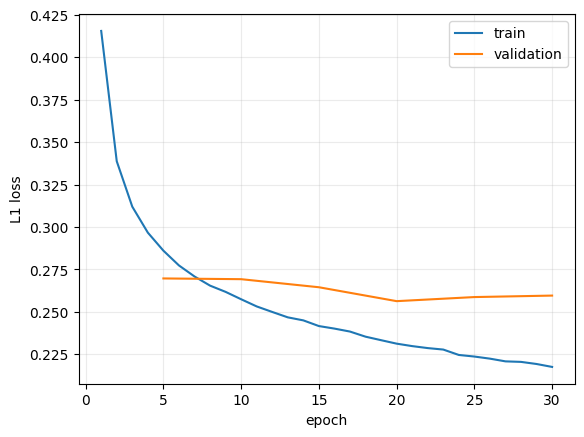

In [31]:
# weight、config、正規化統計、学習履歴を同じdirectoryへ保存します。
training_finished = (
    globals().get('TRAINING_COMPLETE', False)
    and len(history) == EPOCHS
    and history[-1]['epoch'] == EPOCHS
)
if not training_finished:
    raise RuntimeError(f'{EPOCHS} epochの学習が完了していないため、checkpointを保存できません。')

CHECKPOINT_DIR = Path('artifacts/checkpoints/lerobot-act')
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
policy.save_pretrained(CHECKPOINT_DIR)
np.savez(CHECKPOINT_DIR / 'normalization.npz', **{
    f'{key}.{stat}': value for key, values in stats.items() for stat, value in values.items()
})
run_metadata = {
    'dataset': {
        'id': DATASET_ID, 'revision': REVISION,
        'episodes': len(episodes), 'frames': len(actions),
    },
    'training': {
        'seed': SEED, 'epochs': EPOCHS, 'batch_size': BATCH_SIZE,
        'optimizer': 'AdamW', 'learning_rate': LEARNING_RATE,
        'weight_decay': WEIGHT_DECAY, 'torch_threads': torch.get_num_threads(),
    },
    'split': {
        'method': 'episode', 'validation_ratio': 0.2, 'seed': SEED,
        'validation_episodes': validation_episodes.tolist(),
    },
    'environment': {
        'platform': platform.platform(),
        'python': platform.python_version(), 'pytorch': torch.__version__,
        'lerobot': importlib.metadata.version('lerobot'),
        'gym_pusht': importlib.metadata.version('gym-pusht'), 'device': 'cpu',
    },
    'policy_config': 'config.json',
    'seconds': training_seconds, 'history': history,
}
(CHECKPOINT_DIR / 'training_metrics.json').write_text(
    json.dumps(run_metadata, indent=2) + '\n'
)
size = sum(path.stat().st_size for path in CHECKPOINT_DIR.glob('*'))
print(f'Checkpoint: {CHECKPOINT_DIR} ({size / 1024:.1f} KiB)')

plt.plot([row['epoch'] for row in history], [row['train'] for row in history], label='train')
validation_history = [row for row in history if 'validation' in row]
plt.plot(
    [row['epoch'] for row in validation_history],
    [row['validation'] for row in validation_history], label='validation',
)
plt.xlabel('epoch'); plt.ylabel('L1 loss'); plt.grid(alpha=0.25); plt.legend()
plt.show()

## 6. Policyの振る舞いをSimulatorで確かめる【検証】

lossだけではPushTの成功を判断できません。固定した20 seedでSimulatorを動かし、各episodeの最大rewardとsuccess、全体のsuccess rateを記録します。最初に成功したepisodeを動画へ保存し、成功がなければ最大rewardのepisodeを保存します。

> **補足:** ACTは各stepで未来16 actionを予測します。現在実行する1 actionは、過去のstepから重なって予測されたactionをtemporal ensembleでまとめて決めます。


### 評価に使用するcheckpointを読み込む

自分で学習したcheckpointが保存されていればそれを使い、なければ[Hugging Face](https://huggingface.co/cnatsu/roboops-pusht-act)から30 epoch学習済みのcheckpointを取得します。


In [32]:
from huggingface_hub import snapshot_download

MODEL_ID = 'cnatsu/roboops-pusht-act'
MODEL_REVISION = 'ca394daa541d6ac39081f00ce64501de71401c9d'
LOCAL_CHECKPOINT_DIR = Path('artifacts/checkpoints/lerobot-act')
REQUIRED_FILES = ['model.safetensors', 'config.json', 'normalization.npz', 'training_metrics.json']

if all((LOCAL_CHECKPOINT_DIR / name).exists() for name in REQUIRED_FILES):
    CHECKPOINT_DIR = LOCAL_CHECKPOINT_DIR
else:
    CHECKPOINT_DIR = Path('artifacts/checkpoints/lerobot-act-pretrained')
    snapshot_download(
        repo_id=MODEL_ID, revision=MODEL_REVISION,
        local_dir=CHECKPOINT_DIR, allow_patterns=REQUIRED_FILES,
    )

policy = ACTPolicy.from_pretrained(CHECKPOINT_DIR)
with np.load(CHECKPOINT_DIR / 'normalization.npz') as normalization:
    stats = {
        key: {stat: normalization[f'{key}.{stat}'] for stat in ('mean', 'std')}
        for key in MAIN_FIELDS
    }

print(f'Loaded checkpoint: {CHECKPOINT_DIR}')


Loading weights from local directory
Loaded checkpoint: artifacts/checkpoints/lerobot-act


### checkpointをテストする

保存したcheckpointで1回だけ推論し、checkpointの読込から推論までのパイプラインが壊れていないかを確認します。このような確認をテストと呼びます。


In [33]:
# Datasetの先頭recordをPolicyの入力へ変換します。
example = {
    'observation.state': torch.tensor(normalized('observation.state', agent[0])).float().unsqueeze(0),
    'observation.environment_state': torch.tensor(normalized('observation.environment_state', environment[0])).float().unsqueeze(0),
}
policy.eval()
with torch.inference_mode():
    predicted_chunk = policy.predict_action_chunk(example)

assert policy.config.dim_model == 64
assert predicted_chunk.shape == (1, CHUNK_SIZE, 2)
assert torch.isfinite(predicted_chunk).all()
print('PASS: checkpointの読込、Dataset入力、action出力')


PASS: checkpointの読込、Dataset入力、action出力


### SimulatorでPolicyを評価する

読み込んだPolicyを20個の固定seedで動かし、各episodeの最大rewardとsuccessを記録します。各stepでは、観測を正規化してPolicyへ入力し、予測されたactionを元の座標へ戻してSimulatorへ渡します。成功したepisodeがあれば最初の1本を、成功がなければ最大rewardのepisodeを動画として保存します。


In [34]:
EVAL_EPISODES = 20
EVAL_SEED = 1000
MAX_STEPS = 300
VIDEO_PATH = Path('artifacts/evaluation/rollout-lerobot-act.mp4')
results = []
successful_frames = successful_episode = None
best_frames = best_episode = None
best_video_reward = -1.0
env = gym.make(
    'gym_pusht/PushT-v0', obs_type='environment_state_agent_pos',
    render_mode='rgb_array', max_episode_steps=MAX_STEPS,
    visualization_width=384, visualization_height=384,
)
policy.eval()
started = time.perf_counter()
# 評価条件を揃えるため、1000から始まる固定seedを使います。
for episode in range(EVAL_EPISODES):
    observation, _ = env.reset(seed=EVAL_SEED + episode)
    policy.reset()
    initial_coverage = env.unwrapped._get_coverage()
    initial_reward = float(np.clip(initial_coverage / env.unwrapped.success_threshold, 0.0, 1.0))
    maximum_reward, success = initial_reward, False
    episode_frames = (
        [show_reward(env.render(), initial_reward, initial_reward)]
        if successful_frames is None else None
    )
    for _ in range(MAX_STEPS):
        batch = {
            'observation.state': torch.tensor(normalized('observation.state', observation['agent_pos'])).float().unsqueeze(0),
            'observation.environment_state': torch.tensor(normalized('observation.environment_state', observation['environment_state'])).float().unsqueeze(0),
        }
        action = policy.select_action(batch)[0].numpy()
        # Policy出力を元の座標scaleへ戻してからSimulatorへ入力します。
        action = np.clip(action * stats['action']['std'] + stats['action']['mean'], 0, 512)
        observation, reward, terminated, truncated, info = env.step(action)
        maximum_reward = max(maximum_reward, float(reward))
        success = success or bool(info.get('is_success', False))
        if episode_frames is not None:
            episode_frames.append(show_reward(env.render(), float(reward), maximum_reward))
        if terminated or truncated:
            break
    results.append({'seed': EVAL_SEED + episode, 'max_reward': maximum_reward, 'success': success})
    if success and successful_frames is None:
        successful_frames, successful_episode = episode_frames, episode
        best_frames = None
    elif successful_frames is None and maximum_reward > best_video_reward:
        best_frames, best_episode = episode_frames, episode
        best_video_reward = maximum_reward
    if success or (episode + 1) % 5 == 0:
        print(f'{episode + 1:02d}/{EVAL_EPISODES}: reward={maximum_reward:.3f}, success={success}')
env.close()
evaluation_seconds = time.perf_counter() - started
frames = successful_frames if successful_frames is not None else best_frames
video_episode = successful_episode if successful_episode is not None else best_episode
video_kind = 'successful' if successful_frames is not None else 'best reward'
VIDEO_PATH.parent.mkdir(parents=True, exist_ok=True)
iio.imwrite(VIDEO_PATH, np.stack(frames), fps=10, codec='libx264')
print(f"Video: {video_kind} episode / seed={EVAL_SEED + video_episode}")


05/20: reward=0.199, success=False
10/20: reward=0.758, success=False
15/20: reward=0.184, success=False
20/20: reward=0.081, success=False
Video: best reward episode / seed=1010


In [35]:
mean_reward = float(np.mean([row['max_reward'] for row in results]))
success_rate = float(np.mean([row['success'] for row in results]))
# 集計値とepisodeごとの結果を同じJSONへ保存します。
metrics = {
    'checkpoint': str(CHECKPOINT_DIR),
    'dataset': {'id': DATASET_ID, 'revision': REVISION},
    'evaluation': {
        'episodes': EVAL_EPISODES, 'seed': EVAL_SEED, 'max_steps': MAX_STEPS,
    },
    'mean_max_reward': mean_reward, 'success_rate': success_rate,
    'seconds': evaluation_seconds, 'episode_results': results,
}
METRICS_PATH = Path('artifacts/evaluation/metrics-lerobot-act.json')
METRICS_PATH.write_text(json.dumps(metrics, indent=2) + '\n')
assert METRICS_PATH.exists()
print(f'Mean max reward: {mean_reward:.3f}')
print(f'Success rate: {success_rate:.0%}')
print(f'Evaluation: {evaluation_seconds:.1f}秒')
display(Video(str(VIDEO_PATH), embed=True, width=480))


Mean max reward: 0.383
Success rate: 0%
Evaluation: 67.8秒
